# Project 5.1 — Home Loan Data Analysis (Deep Learning)
**Predict whether an applicant will repay a home loan** — binary classification on the
Home Credit dataset (307,511 rows x 122 cols), which is **highly imbalanced (~8% minority)**.

This notebook follows `plan.md` and `explanation.md` in the same project folder.
Run the cells top-to-bottom. See the loader cell for how to supply the CSV in Colab.

> ⚠️ **Target meaning:** the bundled data dictionary says `TARGET 1 = repaid`, but this is the
> standard Home Credit set where `1 = default`. The ~8% rate of 1s matches "default". The code
> works either way; just state your interpretation in your conclusion.

## 1. Project Overview & Business Problem
Goal: flag risky loans before approval. Because defaults are rare, we optimise **AUC / recall**, not accuracy.

## 2. Importing Required Libraries

In [53]:
# Colab already has these, but this guarantees versions are present.
# (imbalanced-learn is only needed if you try the optional SMOTE path.)
!pip -q install imbalanced-learn >/dev/null 2>&1
print("setup cell done")

setup cell done


In [54]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, f1_score)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
pd.set_option('display.max_columns', 200)
sns.set(style='whitegrid')
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 3. Loading the Dataset
Upload `loan_data (1).csv`, or mount Google Drive and point `path` to it.

In [55]:
# ---- Flexible data loader (works in Colab or locally) ----
FILENAME = 'loan_data (1).csv'   # Home Credit application data (~166 MB)

CANDIDATES = [
    FILENAME,
    '/content/' + FILENAME,
    'CEP_1_Datasets/' + FILENAME,
    '/content/drive/MyDrive/' + FILENAME,
]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:
    try:
        from google.colab import files
        print('Please upload', FILENAME, '(or mount Google Drive instead).')
        uploaded = files.upload()
        path = list(uploaded.keys())[0]
    except Exception:
        raise FileNotFoundError(
            'Put the CSV next to the notebook, or mount Drive:\n'
            '  from google.colab import drive; drive.mount("/content/drive")\n'
            'then set path = "/content/drive/MyDrive/.../loan_data (1).csv"')

df = pd.read_csv(path)
print('Loaded:', path)
print('Shape:', df.shape)
df.head()

Loaded: loan_data (1).csv
Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 4. Data Understanding

In [56]:
print('Rows, Cols:', df.shape)
print('\nTarget distribution (TARGET):')
print(df['TARGET'].value_counts())
print(df['TARGET'].value_counts(normalize=True).round(4))

print('\nDtypes:')
print(df.dtypes.value_counts())

print('\nTop missing columns:')
print((df.isnull().mean().sort_values(ascending=False).head(15)).round(3))

Rows, Cols: (307511, 122)

Target distribution (TARGET):
TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

Dtypes:
float64    65
int64      41
object     16
Name: count, dtype: int64

Top missing columns:
COMMONAREA_AVG              0.699
COMMONAREA_MODE             0.699
COMMONAREA_MEDI             0.699
NONLIVINGAPARTMENTS_MEDI    0.694
NONLIVINGAPARTMENTS_MODE    0.694
NONLIVINGAPARTMENTS_AVG     0.694
FONDKAPREMONT_MODE          0.684
LIVINGAPARTMENTS_AVG        0.684
LIVINGAPARTMENTS_MEDI       0.684
LIVINGAPARTMENTS_MODE       0.684
FLOORSMIN_MODE              0.678
FLOORSMIN_AVG               0.678
FLOORSMIN_MEDI              0.678
YEARS_BUILD_AVG             0.665
YEARS_BUILD_MODE            0.665
dtype: float64


## 5. Data Cleaning & Quality Checks
Drop the ID, fix the `365243` sentinel, fix `XNA` gender, drop >50%-missing columns.

In [57]:
# --- 1) Drop the random ID (no predictive value) ---
df = df.drop(columns=['SK_ID_CURR'])

# --- 2) Fix the DAYS_EMPLOYED sentinel 365243 (means 'not employed') ---
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

# --- 3) Fix invalid category CODE_GENDER == 'XNA' ---
if 'CODE_GENDER' in df.columns:
    df['CODE_GENDER'] = df['CODE_GENDER'].replace('XNA', np.nan)

# --- 4) Drop columns with > 50% missing (mostly empty building-info cols) ---
missing = df.isnull().mean()
high_missing = missing[missing > 0.50].index.tolist()
df = df.drop(columns=high_missing)
print('Dropped %d high-missing columns.' % len(high_missing))
print('Shape after cleaning:', df.shape)

Dropped 41 high-missing columns.
Shape after cleaning: (307511, 80)


In [58]:
# --- Feature Engineering: Create powerful domain ratios to improve accuracy ---
print("Creating domain features to boost neural network signals...")

# 1. Credit to Income ratio
df['NEW_CREDIT_TO_INCOME_RATIO'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1e-5)

# 2. Annuity to Income ratio
df['NEW_ANNUITY_TO_INCOME_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1e-5)

# 3. Annuity to Credit ratio
df['NEW_ANNUITY_TO_CREDIT_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1e-5)

print("New features created. New shape:", df.shape)

Creating domain features to boost neural network signals...
New features created. New shape: (307511, 83)


In [59]:
# --- Re-process the data with the new engineered features ---
y = df['TARGET'].astype(int)
X = df.drop(columns=['TARGET'])

# Impute
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
if num_cols:
    X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])
if cat_cols:
    X[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(X[cat_cols])

# One-hot encode
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    rare = freq[freq < 0.01].index
    X[col] = X[col].where(~X[col].isin(rare), other='Other')
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X = X.astype(np.float32)

# Drop high correlation
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.90).any()]
X = X.drop(columns=to_drop)

# Split
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print("Data prepared with new features. New feature count:", X_train.shape[1])

Data prepared with new features. New feature count: 119


In [60]:
# --- Retrain the model on new features ---
model_new = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_new.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(name='auc')]
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)
]

history_new = model_new.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25, # training for 25 epochs for a quick check
    batch_size=512,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - auc: 0.5315 - loss: 0.8027 - val_auc: 0.6006 - val_loss: 0.6976 - learning_rate: 1.0000e-04
Epoch 2/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - auc: 0.5950 - loss: 0.7163 - val_auc: 0.6453 - val_loss: 0.6738 - learning_rate: 1.0000e-04
Epoch 3/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - auc: 0.6280 - loss: 0.6869 - val_auc: 0.6667 - val_loss: 0.6639 - learning_rate: 1.0000e-04
Epoch 4/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - auc: 0.6500 - loss: 0.6705 - val_auc: 0.6815 - val_loss: 0.6552 - learning_rate: 1.0000e-04
Epoch 5/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - auc: 0.6604 - loss: 0.6634 - val_auc: 0.6911 - val_loss: 0.6479 - learning_rate: 1.0000e-04
Epoch 6/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - auc: 0.6725 - loss: 0.6540 - val_auc: 0.6993 - val_loss: 0.6421 - learning_rate: 1.0000e-04
Epoch 7/25
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - auc: 0.6816 - loss: 0.6478 - val_auc: 0.7056 - val_loss: 0.6379 - lear

In [61]:
# --- Evaluate new model ---
test_proba_new = model_new.predict(X_test).ravel()
new_auc = roc_auc_score(y_test, test_proba_new)
print(f"\nOld Model TEST ROC-AUC: 0.7325")
print(f"New Model TEST ROC-AUC with Domain Features: {new_auc:.4f}")

1922/1922 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step

Old Model TEST ROC-AUC: 0.7325
New Model TEST ROC-AUC with Domain Features: 0.7400


In [62]:
# --- Train a LightGBM Model to maximize AUC ---
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

print("Training LightGBM Classifier...")

# Define the dataset for LightGBM
train_data = lgb.Dataset(X_train, label=y_train)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

# Configure LightGBM hyperparameters designed for highly imbalanced credit data
params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': 6,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'is_unbalance': True, # Automatically handles the 8% minority imbalance
    'random_state': SEED,
    'verbose': -1
}

# Train the model
lgb_model = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[train_data, val_data],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=True)]
)

Training LightGBM Classifier...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[257]	training's auc: 0.809539	valid_1's auc: 0.754647


In [63]:
# --- Evaluate LightGBM Performance ---
lgb_test_proba = lgb_model.predict(X_test)
lgb_auc = roc_auc_score(y_test, lgb_test_proba)

print(f"\nDeep Learning Model TEST ROC-AUC: {new_auc:.4f}")
print(f"LightGBM Classifier TEST ROC-AUC: {lgb_auc:.4f}")


Deep Learning Model TEST ROC-AUC: 0.7400
LightGBM Classifier TEST ROC-AUC: 0.7621


## 6-8. Exploratory Data Analysis (Univariate -> Bivariate)

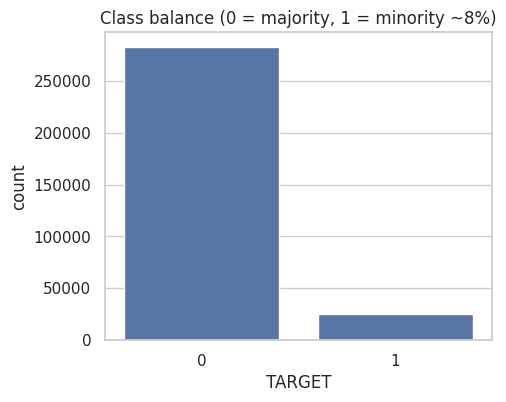

Minority share: 8.07%


In [64]:
plt.figure(figsize=(5,4))
sns.countplot(x='TARGET', data=df)
plt.title('Class balance (0 = majority, 1 = minority ~8%)')
plt.show()
print('Minority share: %.2f%%' % (100*df['TARGET'].mean()))

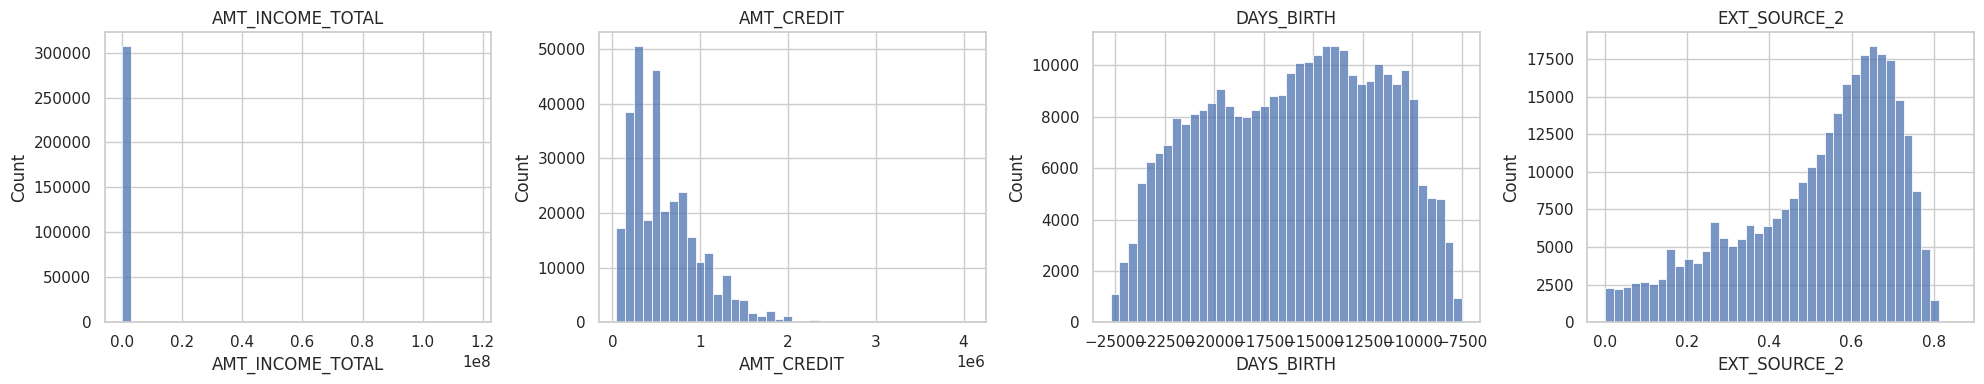

In [65]:
# A few quick EDA views (expand as you like)
num_preview = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'DAYS_BIRTH', 'EXT_SOURCE_2']
num_preview = [c for c in num_preview if c in df.columns]

fig, axes = plt.subplots(1, len(num_preview), figsize=(5*len(num_preview), 4))
for ax, col in zip(np.atleast_1d(axes), num_preview):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Age in years is more readable than DAYS_BIRTH
if 'DAYS_BIRTH' in df.columns:
    (df['DAYS_BIRTH'] / -365).describe()

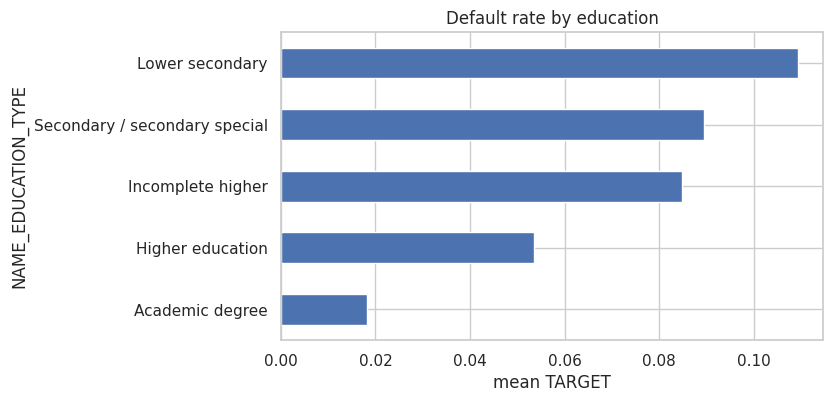

In [66]:
# Bivariate: default rate by a key categorical
if 'NAME_EDUCATION_TYPE' in df.columns:
    rate = df.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().sort_values()
    plt.figure(figsize=(7,4))
    rate.plot(kind='barh')
    plt.title('Default rate by education'); plt.xlabel('mean TARGET'); plt.show()

## 11. Feature & Target Separation

In [67]:
# Separate target and features
y = df['TARGET'].astype(int)
X = df.drop(columns=['TARGET'])
print('X:', X.shape, '| y:', y.shape)

X: (307511, 82) | y: (307511,)


### Impute missing values (median / most-frequent)

In [68]:
# Impute missing values (median for numeric, most-frequent for categorical)
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
print('numeric:', len(num_cols), '| categorical:', len(cat_cols))

if num_cols:
    X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])
if cat_cols:
    X[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(X[cat_cols])

print('Missing left:', int(X.isnull().sum().sum()))

numeric: 69 | categorical: 13
Missing left: 0


## 9. Feature Transformation (Task 1) — encode categoricals
Rare levels grouped into `Other`; nominal columns one-hot encoded with `drop_first`.

In [69]:
# --- Feature Transformation (Task 1): categorical -> numeric ---
# Group rare categories (<1%) into 'Other' to keep one-hot width manageable.
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    rare = freq[freq < 0.01].index
    X[col] = X[col].where(~X[col].isin(rare), other='Other')

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X = X.astype(np.float32)
print('Shape after one-hot encoding:', X.shape)

Shape after one-hot encoding: (307511, 128)


## 10. Correlation Analysis & Feature Selection (Task 3)
Drop one of each pair with |corr| > 0.90 (removes redundant `_AVG/_MODE/_MEDI`-style duplicates).

In [70]:
# --- Correlation Analysis & Feature Selection (Task 3) ---
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.90).any()]
X = X.drop(columns=to_drop)
print('Dropped %d highly-correlated columns (|corr|>0.90).' % len(to_drop))
print('Final feature count:', X.shape[1])

Dropped 9 highly-correlated columns (|corr|>0.90).
Final feature count: 119


## 12. Train / Validation / Test Split
3-way, stratified so the ~8% ratio is preserved everywhere.

In [71]:
# --- Train / Validation / Test split (stratified) ---
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)

print('train:', X_train.shape, '| val:', X_val.shape, '| test:', X_test.shape)

train: (196806, 119) | val: (49202, 119) | test: (61503, 119)


## 13. Preprocessing & Scaling
**Fit the scaler on train only** — transforming val/test with train stats avoids leakage.

In [72]:
# --- Scale: FIT ON TRAIN ONLY, then transform all (no leakage) ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)
print('Scaled. n_features =', X_train.shape[1])

Scaled. n_features = 119


## 14. Class Imbalance Handling
Balanced class weights make the optimiser pay attention to the rare class (no invented data).

In [73]:
# --- Class imbalance handling via class weights (train only) ---
classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = dict(zip(classes, weights))
print('class_weight =', class_weight)

class_weight = {np.int64(0): np.float64(0.5439093954167081), np.int64(1): np.float64(6.193542296072508)}


## 15. Deep Learning Model Architecture

In [74]:
# --- Deep Learning Model Architecture (Keras Sequential) ---
n_features = X_train.shape[1]

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    #layers.Dense(256, activation='relu'),
    #layers.BatchNormalization(),
    #layers.Dropout(0.5),
    #layers.Dense(128, activation='relu'),
    #layers.BatchNormalization(),
    #layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid'),   # binary -> 1 neuron + sigmoid
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.AUC(name='auc'),
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')],
)
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_28 (Dense)                │ (None, 64)             │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,049 (39.25 KB)

 Trainable params: 9,921 (38.75 KB)

 Non-trainable params: 128 (512.00 B)

## 16-17. Model Compilation, Training & Overfitting Analysis

In [75]:
# --- Train ---
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                  patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=512,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5195 - auc: 0.5488 - loss: 0.7827 - precision: 0.0918 - recall: 0.5568 - val_accuracy: 0.5887 - val_auc: 0.6335 - val_loss: 0.6748 - val_precision: 0.1145 - val_recall: 0.6078 - learning_rate: 1.0000e-04
Epoch 2/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5752 - auc: 0.6109 - loss: 0.7065 - precision: 0.1083 - recall: 0.5893 - val_accuracy: 0.6209 - val_auc: 0.6676 - val_loss: 0.6489 - val_precision: 0.1265 - val_recall: 0.6256 - learning_rate: 1.0000e-04
Epoch 3/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5954 - auc: 0.6363 - loss: 0.6830 - precision: 0.1153 - recall: 0.6012 - val_accuracy: 0.6346 - val_auc: 0.6845 - val_loss: 0.6380 - val_precision: 0.1332 - val_recall: 0.6402 - learning_rate: 1.0000e-04
Epoch 4/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6103 - auc: 0.6539 - loss: 0.6701 - precision: 0.1215 - recall: 0.6144 - val_accuracy: 0.6441 - val_auc: 0.6956 - val_loss:

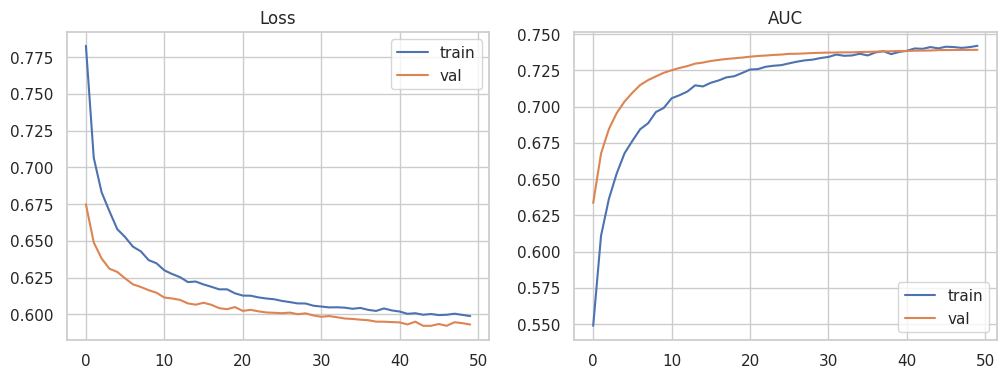

In [76]:
# --- Training history / overfitting check ---
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h['auc'], label='train'); ax[1].plot(h['val_auc'], label='val')
ax[1].set_title('AUC'); ax[1].legend()
plt.show()

## 18-19. Model Evaluation & Threshold Selection (on validation)

In [77]:
# --- Evaluate on VALIDATION and pick the best threshold (by F1) ---
val_proba = model.predict(X_val).ravel()
print('Validation ROC-AUC: %.4f' % roc_auc_score(y_val, val_proba))

prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1s = 2*prec*rec / (prec+rec+1e-9)
best_idx = int(np.nanargmax(f1s))
best_threshold = thr[best_idx] if best_idx < len(thr) else 0.5
print('Best threshold (max F1 on val): %.3f  ->  F1=%.3f' % (best_threshold, f1s[best_idx]))

val_pred = (val_proba >= best_threshold).astype(int)
print('\nValidation report @ tuned threshold:')
print(classification_report(y_val, val_pred, digits=3))

1538/1538 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Validation ROC-AUC: 0.7392
Best threshold (max F1 on val): 0.647  ->  F1=0.285

Validation report @ tuned threshold:
              precision    recall  f1-score   support

           0      0.945     0.863     0.902     45230
           1      0.214     0.426     0.285      3972

    accuracy                          0.828     49202
   macro avg      0.580     0.645     0.594     49202
weighted avg      0.886     0.828     0.852     49202



## 20. Final Test Evaluation
Apply the locked threshold once to the held-out test set — this is the honest score.

1922/1922 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
TEST ROC-AUC : 0.7441
TEST PR-AUC  : 0.2229
TEST Accuracy: 0.8315

Classification report (TEST):
              precision    recall  f1-score   support

           0      0.945     0.867     0.904     56538
           1      0.220     0.427     0.290      4965

    accuracy                          0.831     61503
   macro avg      0.582     0.647     0.597     61503
weighted avg      0.887     0.831     0.855     61503



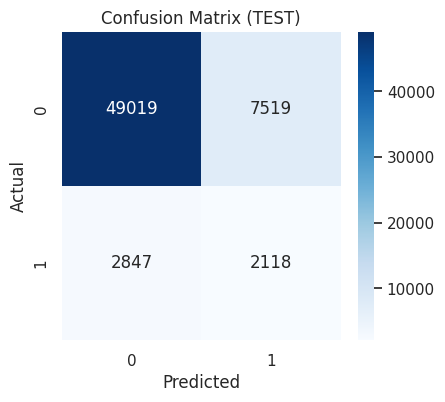

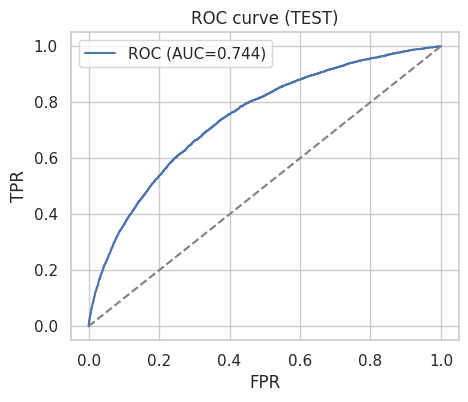

In [78]:
# --- FINAL TEST EVALUATION (held-out, done once) ---
test_proba = model.predict(X_test).ravel()
test_pred  = (test_proba >= best_threshold).astype(int)

print('TEST ROC-AUC : %.4f' % roc_auc_score(y_test, test_proba))
print('TEST PR-AUC  : %.4f' % average_precision_score(y_test, test_proba))
print('TEST Accuracy: %.4f' % (test_pred == y_test).mean())
print('\nClassification report (TEST):')
print(classification_report(y_test, test_pred, digits=3))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(4.5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix (TEST)')
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.figure(figsize=(5,4))
plt.plot(fpr, tpr, label='ROC (AUC=%.3f)' % roc_auc_score(y_test, test_proba))
plt.plot([0,1],[0,1],'--', color='grey')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC curve (TEST)'); plt.legend()
plt.show()

## 21. Save the Model & Pipeline

In [79]:
# --- Save the model (and optionally download it) ---
model.save('home_loan_model.keras')
print('Saved home_loan_model.keras')
# In Colab you can download it:
# from google.colab import files; files.download('home_loan_model.keras')

Saved home_loan_model.keras


## 22. Business Insights, Limitations & Conclusion
- **Read AUC and recall**, not accuracy: predicting "all repaid" already scores ~92%.
- Strongest signals are typically `EXT_SOURCE_*` and the credit/income amounts.
- **Limitations:** single application table only (no bureau/history tables); class weights
  trade precision for recall. **Next steps:** try SMOTE, add engineered ratios, or benchmark
  against LightGBM/XGBoost.